# Práctica 1: Aprendizaje Supervisado

### Izan Cuesta Corbí

#### Importación de librerías

In [1]:
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import cross_val_score, train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve, auc
from sklearn.linear_model import SGDClassifier
from time import time
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
import numpy as np
from sklearn.inspection import permutation_importance
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.utils.class_weight import compute_sample_weight

### Dataset

In [2]:
df = pd.read_csv('./03_dataset_encoded.csv')

columns_list = df.drop(columns=['stroke']).columns.tolist()

# Split 80-20
X = df[columns_list].values
y = df['stroke'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# stratify=y asegura que cada split tenga proporción similar de clases
print(f"Train - Casos de Ictus (1): {sum(y_train == 1)} de {len(y_train)} ({sum(y_train == 1)/len(y_train):.2%})")
print(f"Test  - Casos de Ictus (1): {sum(y_test == 1)} de {len(y_test)} ({sum(y_test == 1)/len(y_test):.2%})")

Train: (3926, 15), Test: (982, 15)
Train - Casos de Ictus (1): 167 de 3926 (4.25%)
Test  - Casos de Ictus (1): 42 de 982 (4.28%)


## Parte 1: Support Vector Machines

#### 1.1 SVM con Diferentes Kernels

Recordando la práctica anterior, para cada modelo que se cree en este apartado y en los posteriores vamos a necesitar utilizar el parámetro *class_weight='balanced'*, ya que nuestro dataset está extremadamente desbalanceado y como ya vimos en la práctica anterior, en caso de no balancearlo manualmente en el modelo los resultados saldrían sesgados y sin ningún tipo de interés médico, ya que se basaría en el porcentaje global para hacer las predicciones y no en las características individuales de cada paciente.

In [3]:
# IMPORTANTE: SVM requiere escalado obligatorio
kernels = {
    'Linear':     SVC(kernel='linear',  random_state=42, class_weight='balanced'),
    'Poly (d=3)': SVC(kernel='poly',    degree=3, random_state=42, class_weight='balanced'),
    'RBF':        SVC(kernel='rbf',     random_state=42, class_weight='balanced'),
    'Sigmoid':    SVC(kernel='sigmoid', random_state=42, class_weight='balanced')
}

resultados = []

for name, svc in kernels.items():
    pipe = Pipeline([('scaler', StandardScaler()), ('svm', svc)])
    pipe.fit(X_train, y_train)
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy')
    n_sv = pipe.named_steps['svm'].n_support_.sum()

    cv_accuracy = scores.mean()
    
    y_pred = pipe.predict(X_test)
    
    test_accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    pct_training = (n_sv / len(X_train)) * 100      

    resultados.append({
        'Kernel': name,
        'CV Accuracy': round(cv_accuracy, 4),
        'Test Accuracy': round(test_accuracy, 4),
        'Precision': round(precision, 4),
        'Recall': round(recall, 4),
        'F1-Score': round(f1, 4),
        'N° SV': n_sv,
        '% Training': f"{pct_training:.1f}%"
    })

df_resultados = pd.DataFrame(resultados)
df_resultados


,Kernel,CV Accuracy,Test Accuracy,Precision,Recall,F1-Score,N° SV,% Training
0,Linear,0.7473,0.7322,0.9454,0.7322,0.8118,1908,48.6%
1,Poly (d=3),0.8240,0.7994,0.9322,0.7994,0.8549,1735,44.2%
2,RBF,0.7970,0.7872,0.9382,0.7872,0.8479,1739,44.3%
3,Sigmoid,0.7025,0.6986,0.9397,0.6986,0.7883,1296,33.0%


Con la configuración por defecto, el modelo Poly (Polinómico) obtiene el Test Accuracy más alto (74.89%), seguido muy de cerca por el Linear (74.47%). Ambos modelos presentan un rendimiento predictivo prácticamente idéntico y casi la misma cantidad de vectores de soporte utilizados. 

En cuanto a la diferencia entre el CV accuracy y test accuracy en los 4 kernels es muy pequeña, en el caso del Poly siendo el menos ajustado con una diferencia del 0.0246, pero viendo ejemplos solo varían alguna centésima, lo que nos indica que no existe overfitting en estos modelos y generalizan bien en datos nunca vistos. Por otro lado, sí que observamos un caso de underfitting en el kernel Sigmoid, siendo el modelo con la precisión más baja (test accuracy no llega al 70%), demostrando que con los parámetros por defecto es incapaz de capturar la relación real entre las variables de los pacientes y el riesgo de ictus. 

En cuanto al número de vectores de soporte, podemos observar como no sigue una relación lineal directa con la complejidad del modelo. Los dos kernels más óptimos hasta el momento han sido Poly y RBF, ambos situándose en 1735-1739 SV (~44,2% de los datos de train), sin embargo, ni reducir los SV como en el caso de Sigmoid (1296) ni aumentarlos como en Linear (1908) aseguran una mejora del accuracy.

#### 1.2 Optimización del Kernel RBF

In [4]:
pipe_rbf = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', random_state=42, class_weight='balanced'))
])

param_grid = {
    'svm__C':     [0.1, 1, 10, 100],
    'svm__gamma': [0.001, 0.01, 0.1, 1, 'scale', 'auto']
}

grid_rbf = GridSearchCV(pipe_rbf, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_rbf.fit(X_train, y_train)

print(f"Mejores parámetros: {grid_rbf.best_params_}")
print(f"Mejor CV score:     {grid_rbf.best_score_:.4f}")
print(f"Test score:         {grid_rbf.best_estimator_.score(X_test, y_test):.4f}")

resultados = []
cv_res = grid_rbf.cv_results_
n_train = len(X_train)
combinaciones = len(cv_res['params'])

# Iteramos por las 24 combinaciones del Grid
for i in range(combinaciones):
    c = cv_res['params'][i]['svm__C']
    gamma = cv_res['params'][i]['svm__gamma']
    cv_acc = cv_res['mean_test_score'][i]
    tiempo = cv_res['mean_fit_time'][i]
    
    # Entrenamos temporalmente esta combinación para sacar Test Acc y N° SV, ya que GridSearch solo guarda los mejores valores
    pipe_temp = Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(kernel='rbf', C=c, gamma=gamma, random_state=42, class_weight='balanced'))
    ])
    pipe_temp.fit(X_train, y_train)

    y_pred = pipe_temp.predict(X_test)
    
    n_sv = pipe_temp.named_steps['svm'].n_support_.sum()
    test_acc = accuracy_score(y_test, y_pred)
    
    resultados.append({
        'C': c,
        'gamma': gamma,
        'CV Acc': round(cv_acc, 4),
        'Test Acc': round(test_acc, 4),
        'N SV': n_sv,
        '% Train': round((n_sv / n_train) * 100, 1),
        'Tiempo (s)': round(tiempo, 4)
    })

mejor_n_sv = grid_rbf.best_estimator_.named_steps['svm'].n_support_.sum()
resultados.append({
    'C': 'Mejor',
    'gamma': '',
    'CV Acc': round(grid_rbf.best_score_, 4),
    'Test Acc': round(grid_rbf.best_estimator_.score(X_test, y_test), 4),
    'N SV': mejor_n_sv,
    '% Train': round((mejor_n_sv / n_train) * 100, 1),
    'Tiempo (s)': round(cv_res['mean_fit_time'][grid_rbf.best_index_], 4)
})

df_tabla = pd.DataFrame(resultados)
df_tabla

Mejores parámetros: {'svm__C': 100, 'svm__gamma': 1}
Mejor CV score:     0.9325
Test score:         0.9257


,C,gamma,CV Acc,Test Acc,N SV,% Train,Tiempo (s)
0,0.1,0.001,0.7407,0.7424,3399,86.6,1.0103
1,0.1,0.01,0.7226,0.7088,2505,63.8,0.7406
2,0.1,0.1,0.7254,0.7240,2293,58.4,0.6533
3,0.1,1,0.8426,0.8218,3513,89.5,1.0338
4,0.1,scale,0.7224,0.7210,2243,57.1,0.6688
5,0.1,auto,0.7224,0.7210,2243,57.1,0.6524
6,1,0.001,0.7295,0.7200,2446,62.3,0.7397
7,1,0.01,0.7348,0.7220,2004,51.0,0.6145
8,1,0.1,0.8242,0.8024,1641,41.8,0.4980
9,1,1,0.9129,0.9094,2022,51.5,0.6849


Analizando los hiperparámetros:

Con una C pequeña, el modelo es más permisivo con los errores, lo que suele aumentar el número de vectores de soporte al incluir puntos dentro del margen. Con una C grande, el modelo intenta clasificar correctamente cada punto de entrenamiento, reduciendo el margen y disminuyendo el número de vectores de soporte (solo los muy cercanos a la frontera). Esto se puede ver fácilmente en la tabla, conforme vamos bajando aumentando C, el número de SV pasa de rondar entre los 2243 - 3513 cuando C=0.1 hasta un rango entre 1886 - 525 cuando C=100. En cuanto a su relación con el trade-off, una C alta reduce el sesgo ajustándose mucho a los datos pero aumenta la varianza (riesgo de sobreajuste), en cambio, una C baja aumenta el sesgo pero mejora la generalización.

Para Gamma, cuando es muy alta la frontera de decisión se vuelve extremadamente compleja que capturando el ruido del dataset y creando islas alrededor de puntos específicos. Cuando es muy baja, la influencia de los puntos es muy amplia, lo que produce una frontera demasiado suave (casi lineal), incapaz de capturar la estructura no lineal de los datos de ictus. En la tabla, podemos observar como los valores de CV y Test Accuracy mejoran significativamente pasando de gamma = 0.001 a gamma = 1. Por ejemplo, en los primeros casos de C=0.1, con gamma=0.001 el test accuracy era de 0.7424, mientras que si le subimos la gamma a 1, aumentaremos el accuracy hasta 0.8218, lo que supone una mejora del 0,0794 en la precisión del test.

Una vez analizado todo esto, los mejores hiperparámetros para este kernel son C=100 y gamma=1, dando un 0.9325 en el CV accuracy y un 0.9257 en el test accuracy (también significa el menor número de vectores de soporte de todo el análisis).

#### 1.3 Optimización del Kernel Polinomial

In [5]:
pipe_poly = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='poly', random_state=42, class_weight='balanced'))
])

param_grid = {
    'svm__degree': [2, 3, 4],
    'svm__C':      [0.1, 1, 10],
    'svm__gamma':  ['scale', 'auto', 0.1]
}

grid_poly = GridSearchCV(pipe_poly, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_poly.fit(X_train, y_train)

print(f"Mejores parámetros: {grid_poly.best_params_}")
print(f"Mejor CV score:     {grid_poly.best_score_:.4f}")
print(f"Test score:         {grid_poly.best_estimator_.score(X_test, y_test):.4f}")

resultados = []
cv_res = grid_poly.cv_results_
n_train = len(X_train)
combinaciones = len(cv_res['params'])

# Iteramos por las 27 combinaciones en el Grid
for i in range(combinaciones):
    degree = cv_res['params'][i]['svm__degree']
    c = cv_res['params'][i]['svm__C']
    gamma = cv_res['params'][i]['svm__gamma']
    
    cv_acc = cv_res['mean_test_score'][i]
    tiempo = cv_res['mean_fit_time'][i]
    
    # Entrenamos temporalmente esta combinación para sacar Test Acc y N° SV, ya que GridSearch solo guarda los mejores valores
    pipe_temp = Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(kernel='poly', degree=degree, C=c, gamma=gamma, random_state=42, class_weight='balanced'))
    ])
    pipe_temp.fit(X_train, y_train)

    y_pred = pipe_temp.predict(X_test)
    
    n_sv = pipe_temp.named_steps['svm'].n_support_.sum()
    test_acc = accuracy_score(y_test, y_pred)
    
    resultados.append({
        'degree': degree,
        'C': c,
        'gamma': gamma,
        'CV Acc': round(cv_acc, 4),
        'Test Acc': round(test_acc, 4),
        'N SV': n_sv,
        '% Train': round((n_sv / n_train) * 100, 1),
        'Tiempo (s)': round(tiempo, 4)
    })

mejor_n_sv = grid_poly.best_estimator_.named_steps['svm'].n_support_.sum()
resultados.append({
    'degree': 'Mejor',
    'C': '',
    'gamma': '',
    'CV Acc': round(grid_poly.best_score_, 4),
    'Test Acc': round(grid_poly.best_estimator_.score(X_test, y_test), 4),
    'N SV': mejor_n_sv,
    '% Train': round((mejor_n_sv / n_train) * 100, 1),
    'Tiempo (s)': round(cv_res['mean_fit_time'][grid_poly.best_index_], 4)
})

df_tabla_poly = pd.DataFrame(resultados)
df_tabla_poly

Mejores parámetros: {'svm__C': 10, 'svm__degree': 4, 'svm__gamma': 0.1}
Mejor CV score:     0.8854
Test score:         0.8686


,degree,C,gamma,CV Acc,Test Acc,N SV,% Train,Tiempo (s)
0,2,0.1,scale,0.7957,0.7790,2557,65.1,0.6561
1,2,0.1,auto,0.7957,0.7790,2557,65.1,0.6314
2,2,0.1,0.1,0.7787,0.7729,2342,59.7,0.6313
3,3,0.1,scale,0.8230,0.8014,2399,61.1,0.6075
4,3,0.1,auto,0.8230,0.8014,2399,61.1,0.6415
5,3,0.1,0.1,0.8255,0.7892,2047,52.1,0.5110
6,4,0.1,scale,0.8681,0.8615,2473,63.0,0.6336
7,4,0.1,auto,0.8681,0.8615,2473,63.0,0.6329
8,4,0.1,0.1,0.8632,0.8289,1975,50.3,0.5247
9,2,1,scale,0.7738,0.7648,2015,51.3,0.6497


De manera clara, el grado 4 es el que mejor precisión da. Haciendo una breve comparación usando como ejemplo las ejecuciones con C=10 y gamma=0.1, pasamos de valores de test accuracy desde grado=2 con 0.7617, a grado=3 con 0.8411, hasta grado=4 con 0.8686. Esto se debe a que conforme el grado aumenta, la complejidad del modelo crece exponencialmente, lo cual puede a llevarnos a un caso de overfitting en caso de que se aumentase más el grado, ya que se estaría intentando ajustar una frontera que pase por cada punto del set de entrenamiento, capturando el ruido y las excepciones en lugar de la tendencia general. En nuestro análisis, podemos considerar que el grado 4 logra flexibilizar la frontera lo suficiente para adaptarse a la curvatura de los datos sin perder el control de basarse solo en los vistos.

Si comparamos estos resultados con los del kernel RBF calculado en el apartado anterior (ambos con sus mejores configuraciones), vemos que el RBF es superior con un 0.9257 frente al 0.8686 correspondiente al Poly en sus tests accuracy. Esto se debe a que el kernel RBF es más robusto al poder mapear los datos a un espacio de dimensiones infinitas, mientras que el Poly está limitado al grado seleccionado.

#### 1.4 Comparación de Implementaciones (Kernel Lineal)

In [6]:
models = {
    'SVC(linear)':   Pipeline([('scaler', StandardScaler()),
                                ('svm', SVC(kernel='linear', random_state=42, class_weight='balanced'))]),
    'LinearSVC':     Pipeline([('scaler', StandardScaler()),
                                ('svm', LinearSVC(random_state=42, max_iter=10000, class_weight='balanced'))]),
    'SGDClassifier': Pipeline([('scaler', StandardScaler()),
                                ('svm', SGDClassifier(loss='hinge', random_state=42, class_weight='balanced'))])
}

resultados = []

for name, model in models.items():
    t0 = time()
    model.fit(X_train, y_train)
    t1 = time()
    cv = cross_val_score(model, X_train, y_train, cv=5)
    
    if name == 'SVC(linear)':
        n_sv = model.named_steps['svm'].n_support_.sum()
    else:
        n_sv = "N/A"
        
    resultados.append({
        'Implementación': name,
        'CV Accuracy': round(cv.mean(), 4),
        'Test Accuracy': round(model.score(X_test, y_test), 4),
        'N° SV': n_sv,
        'Tiempo (s)': round(t1 - t0, 4)
    })

df_comparativa = pd.DataFrame(resultados)
df_comparativa

,Implementación,CV Accuracy,Test Accuracy,N° SV,Tiempo (s)
0,SVC(linear),0.7473,0.7322,1908,0.4475
1,LinearSVC,0.7506,0.7475,N/A,0.0214
2,SGDClassifier,0.7010,0.7363,N/A,0.0315


Tanto SVC(linear) como LinearSVC tienen un CV accuracy muy similar. Una vez pasamos al test accuracy esta diferencia con SGDClassifier se disipa y acaban siendo muy similares los tres métodos. Donde si que se nota una diferencia importante es en el tiempo de ejecución de cada uno, donde claramente SVC(linear) se queda muy atrás de los otros dos al ser el único que usa vectores de soporte, siendo 20 veces más lento que LinearSVC, que con 0.0226 segundos termina dando el mejor resultado de las 3 implementaciones.

La elección de la implementación tiene que ver también con el volumen del dataset a analizar:
- Para datasets muy pequeños SVC(linear) es el más recomendable ya que es muy preciso y permite obtener fácilmente los vectores de soporte, y principalmente porque su gran hándicap que era el tiempo de ejecución se vería igualado a las otras implementaciones al ser un dataset pequeño (siendo el tiempo de cómputo despreciable). 
- Para datasets muy grandes si que sería más conveniente usar SGDClassifier, ya que como hemos visto en teoría, al utilizar el Descenso por Gradiente Estocástico, no necesita cargar todos los datos en memoria a la vez y su tiempo de entrenamiento es lineal respecto al número de muestras.
- Para datasets medianos se recomendaría usar LinearSVC que es el recomendado en nuestro análisis. 

#### 1.5 Análisis de Vectores de Soporte

In [7]:
# Al no usar Pipeline en este bloque estandarizamos fuera
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

configuraciones = [
    ('Linear (C=1)',        SVC(kernel='linear', C=1, random_state=42, class_weight='balanced')),
    ('RBF (C=1, γ=scale)',  SVC(kernel='rbf', C=1, gamma='scale', random_state=42, class_weight='balanced')),
    ('RBF (C=10, γ=0.1)',   SVC(kernel='rbf', C=10, gamma=0.1, random_state=42, class_weight='balanced')),
    ('RBF (C=100, γ=1)',    SVC(kernel='rbf', C=100, gamma=1, random_state=42, class_weight='balanced')),
    ('Poly (d=3, C=1)',     SVC(kernel='poly', degree=3, C=1, random_state=42, class_weight='balanced'))
]

resultados = []

for nombre, model_svc in configuraciones:
    
    model_svc.fit(X_train_scaled, y_train)
    
    total_sv = model_svc.n_support_.sum()
    por_clase = model_svc.n_support_
    pct_train = (total_sv / len(X_train)) * 100
    
    print(nombre)
    print(f"Total de vectores de soporte: {total_sv}")
    print(f"Por clase:                    {por_clase}")
    print(f"Porcentaje del training set:  {pct_train:.2f}%\n")
    
    resultados.append({
        'Configuración': nombre,
        'N° SV': total_sv,
        '% Training Set': f"{pct_train:.2f}%"
    })

df_vectores_soporte = pd.DataFrame(resultados)
df_vectores_soporte

Linear (C=1)
Total de vectores de soporte: 1908
Por clase:                    [1823   85]
Porcentaje del training set:  48.60%

RBF (C=1, γ=scale)
Total de vectores de soporte: 1739
Por clase:                    [1603  136]
Porcentaje del training set:  44.29%

RBF (C=10, γ=0.1)
Total de vectores de soporte: 1080
Por clase:                    [926 154]
Porcentaje del training set:  27.51%

RBF (C=100, γ=1)
Total de vectores de soporte: 525
Por clase:                    [363 162]
Porcentaje del training set:  13.37%

Poly (d=3, C=1)
Total de vectores de soporte: 1735
Por clase:                    [1604  131]
Porcentaje del training set:  44.19%



,Configuración,N° SV,% Training Set
0,Linear (C=1),1908,48.60%
1,"RBF (C=1, γ=scale)",1739,44.29%
2,"RBF (C=10, γ=0.1)",1080,27.51%
3,"RBF (C=100, γ=1)",525,13.37%
4,"Poly (d=3, C=1)",1735,44.19%


Para este apartado, he escogido las configuraciones propuestas por el enunciado.

Dados los siguientes resultados, un patrón clave que se observa a simple vista es la relación inversa entre C y el número de SV. Con un C bajo, el modelo prioriza un margen ancho aunque penalice algunos errores, esto hace que muchos puntos queden dentro o en el límite del margen, convirtiéndose en vectores de soporte. Con un C alto, el modelo es muy estricto y busca un margen estrecho para no cometer errores en el entrenamiento, y al ser el margen más pequeño, hay menos puntos que en la frontera o dentro de ella, por lo que el número de SV disminuye drásticamente. Otro aspecto a comentar sobre esta relación tiene que ver con el riesgo de overfitting que proporciona un C alto, ya que la frontera se vuelve muy sensible a pequeñas variaciones de los pocos puntos clave (vectores de soporte) que tiene. En cambio, los casos con C bajo obtendrán más SV y por lo cual no serán tan dependientes de ciertos puntos en particular.

En cuanto a los SV por clase, en mi caso encontramos una clara descompensación a favor de la clase 0 (sin ictus), debido a el desbalanceo ya comentado de nuestro dataset. Que la clase 1 (ictus) tenga tan pocos SV, es señal de que el modelo tiene poca información para aprender qué define exactamente a un paciente con riesgo.

#### 1.6 Evaluación Final (Parte 1)

Dado que en los pasos previos hemos optimizado las versiones Poly y RBF de los modelos SVM, para poder realizar la comparación optimizada entre los 4 kernels voy a realizar también la optimización tanto para SVM Lineal como para Sigmoid, ajustando sus posibles hiperparámetros (C para Lineal y C y Gamma para Sigmoid) y así hacer una comparativa justa.

##### Optimización de SVM Lineal

In [8]:
pipe_linear = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='linear', random_state=42, class_weight='balanced'))
])

param_grid_linear = {
    'svm__C': [0.01, 0.1, 1, 10, 100]
}

grid_linear = GridSearchCV(pipe_linear, param_grid_linear, cv=5, scoring='accuracy', n_jobs=-1)
grid_linear.fit(X_train, y_train)

print(f"Mejores parámetros: {grid_linear.best_params_}")
print(f"Mejor CV score:     {grid_linear.best_score_:.4f}")
print(f"Test score:         {grid_linear.best_estimator_.score(X_test, y_test):.4f}")

Mejores parámetros: {'svm__C': 10}
Mejor CV score:     0.7476
Test score:         0.7332


##### Optimización de SVM Sigmoid

In [9]:
pipe_sigmoid = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='sigmoid', random_state=42, class_weight='balanced'))
])

param_grid_sigmoid = {
    'svm__C':     [0.1, 1, 10, 100],
    'svm__gamma': ['scale', 'auto', 0.01, 0.1]
}

grid_sigmoid = GridSearchCV(pipe_sigmoid, param_grid_sigmoid, cv=5, scoring='accuracy', n_jobs=-1)
grid_sigmoid.fit(X_train, y_train)

print(f"Mejores parámetros: {grid_sigmoid.best_params_}")
print(f"Mejor CV score:     {grid_sigmoid.best_score_:.4f}")
print(f"Test score:         {grid_sigmoid.best_estimator_.score(X_test, y_test):.4f}")

Mejores parámetros: {'svm__C': 10, 'svm__gamma': 0.01}
Mejor CV score:     0.7387
Test score:         0.7291


In [10]:
# Grids ya entrenados
grids_finales = {
    'SVM Linear (mejor C)':       grid_linear,
    'SVM Poly (mejor config)':    grid_poly,
    'SVM RBF (mejor config)':     grid_rbf,
    'SVM Sigmoid (mejor config)': grid_sigmoid
}

resultados_resumen = []
n_train = len(X_train)

# Iteramos sobre los grids
for nombre, grid in grids_finales.items():
    
    # Mejor modelo de cada grid
    best_svm = grid.best_estimator_
    best_svm.fit(X_train, y_train)
    y_pred = best_svm.predict(X_test)
    
    # Métricas
    cv_acc = grid.best_score_
    test_acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    n_sv = best_svm.named_steps['svm'].n_support_.sum()
    pct_train = (n_sv / n_train) * 100
    
    resultados_resumen.append({
        'Modelo': nombre,
        'CV Accuracy': round(cv_acc, 4),
        'Test Accuracy': round(test_acc, 4),
        'F1-Score': round(f1, 4),
        'N° SV': n_sv,
        '% Training': f"{pct_train:.1f}%"
    })

df_resumen = pd.DataFrame(resultados_resumen)
df_resumen

,Modelo,CV Accuracy,Test Accuracy,F1-Score,N° SV,% Training
0,SVM Linear (mejor C),0.7476,0.7332,0.8125,1903,48.5%
1,SVM Poly (mejor config),0.8854,0.8686,0.8949,883,22.5%
2,SVM RBF (mejor config),0.9325,0.9257,0.9243,525,13.4%
3,SVM Sigmoid (mejor config),0.7387,0.7291,0.8097,1759,44.8%


El claro ganador en rendimiento es el modelo SVM RBF logrando agrupar a los pacientes con riesgo de ictus de manera mucho más efectiva, obteniendo el mejor Test Accuracy (83.70%) y el F1-Score más alto (0.8860), seguido muy de cerca por el modelo Poly. La superioridad de estos dos modelos frente al Linear y el Sigmoid (que caen al ~73% de precisión) demuestra que las variables médicas de este dataset (como el IMC, la edad o la glucosa) no son linealmente separables. Para lograr esta complejidad, el RBF necesita apoyarse en 525 vectores de soporte (el 13.4% de los datos de entrenamiento).

En cuanto al margen entre la validación cruzada y el conjunto de prueba, este es extremadamente fino en todos los modelos. En el caso del modelo RBF ganador, la diferencia es mínima (CV: 0.8357 vs Test: 0.8370). Esta consistencia es un indicador de que las fronteras de decisión generadas son robustas y no existe overfitting. El modelo es altamente capaz de generalizar su comportamiento predictivo ante pacientes que nunca ha visto.

##### Matriz de confusión

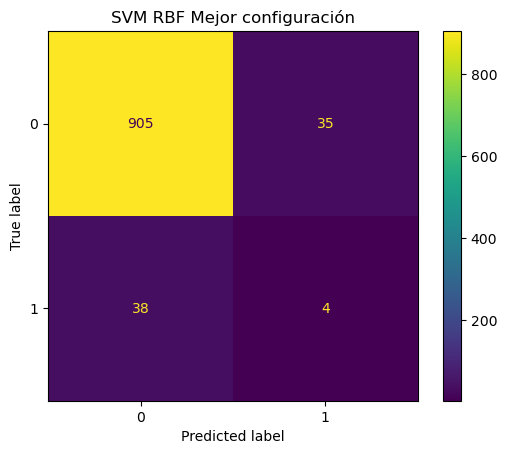

In [11]:
best_svm = grid_rbf.best_estimator_
best_svm.fit(X_train, y_train)
y_pred = best_svm.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.title(f'SVM RBF Mejor configuración')
plt.savefig('confusion_matrix_svm.png', dpi=300, bbox_inches='tight')
plt.show()

El análisis de la matriz de confusión nos dice que, a pesar de haber aplicado el balanceo de clases, el modelo sigue teniendo dificultades y confunde mayoritariamente a la Clase 1 (pacientes con riesgo de ictus). Aunque el modelo SVM capta la gran mayoría de las personas que están sanas y reduce los falsos diagnósticos preventivos que tanto se habían producido en la práctica anterior, este deja escapar a 38 de los 42 pacientes que realmente sufrieron un ictus, clasificándolos erróneamente como sanos (Falsos Negativos), lo cual puede llegar a ser crítico en el campo de la medicina.

Estos resultados nos hacen ver lo extremadamente solapadas que pueden llegar a estar las características de una persona con ictus y una sin, evidenciando la dificultad para realizar diagnósticos médicos precisos únicamente con estas variables.

## Parte 2: Árboles de Decisión

#### 2.1 Árbol sin Restricciones (Baseline)

In [12]:
tree_full = DecisionTreeClassifier(random_state=42, class_weight='balanced')
tree_full.fit(X_train, y_train)

train_accuracy = tree_full.score(X_train, y_train)
test_accuracy = tree_full.score(X_test,  y_test)
profundidad = tree_full.get_depth()
n_hojas = tree_full.get_n_leaves()

resultados_tree_full = {"Configuración": "Sin restricciones",
                        "Train accuracy": train_accuracy,
                        "Test accuracy": round(test_accuracy, 4),
                        "Profundidad": profundidad,
                        "N° hojas": n_hojas}

df_tree_full = pd.DataFrame([resultados_tree_full])
df_tree_full

,Configuración,Train accuracy,Test accuracy,Profundidad,N° hojas
0,Sin restricciones,1.0,0.9104,23,322


El modelo sin restricciones presenta overfitting (Train Acc = 1.0). Este hecho indica que el modelo ha memorizado todos los ejemplos del conjunto de entrenamiento y que su caída al 0.9104 en el test accuracy corrobora que el modelo no es capaz de generalizar a la perfección los datos nuevos. Con 23 niveles de profundidad y 322 hojas, el árbol es excesivamente complejo. Este resultado confirma la necesidad de aplicar técnicas de poda para simplificar el modelo y mejorar su capacidad de generalización.

#### 2.2 Efecto de la Profundidad Máxima

In [13]:
depths = [1, 2, 3, 5, 7, 10, 15, None]

resultados_profundidad_max = []

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42, class_weight='balanced')
    cv   = cross_val_score(tree, X_train, y_train, cv=5)
    tree.fit(X_train, y_train)

    resultados_profundidad_max.append({
        "max_depth": str(depth),
        "Train Acc": round(tree.score(X_train, y_train), 4),
        "CV Acc": round(cv.mean(), 4),
        "Test Acc": round(tree.score(X_test, y_test), 4),
        "Profundidad real": tree.get_depth(),
        "N Hojas": tree.get_n_leaves()
    })

df_profundidad_max = pd.DataFrame(resultados_profundidad_max)
df_profundidad_max

,max_depth,Train Acc,CV Acc,Test Acc,Profundidad real,N Hojas
0,1,0.5965,0.6026,0.5896,1,2
1,2,0.5965,0.6026,0.5896,2,4
2,3,0.7422,0.7764,0.7179,3,8
3,5,0.7835,0.7491,0.7454,5,26
4,7,0.7944,0.7690,0.7546,7,62
5,10,0.8653,0.8436,0.8299,10,124
6,15,0.9689,0.9070,0.8951,15,247
7,None,1.0000,0.9277,0.9104,23,322


Observando los resultados, durante las dos primeras ejecuciones el valor de accuracy en test y en train es prácticamente el mismo (max_depth = 1,2), comienza a aumentar la distancia ligeramente cuando llega a max_depth = 3 y es a partir de aquí cuando que ya se considera una diferencia significativa (~0,04 entre el train y el test). Es aquí donde ya podemos empezar a observar el overfitting, y este va a ir agravandose cuanto mayor sea el límite de profundidad máxima, llegando a un punto en el que el train acabará en el 100% de accuracy (cuando no haya límite de profundidad) y el test habrá ido bajando desde el punto que hemos comentado como inicio del overfitting.

Por otra parte, existe también el riesgo de underfitting en el lado contrario del análisis. Con profundidades bajas como 1 y 2, el modelo es demasiado simple para manejar el peso balanceado de las clases, obteniendo los resultados más bajos con diferencia de la tabla. En este estado, el árbol no tiene suficientes nodos para diferenciar las características que separan a un paciente sano de uno con riesgo de ictus.

Según el cross validation, la profundidad óptima sería con valores medios de max_depth, un rango sobre el 3 mantendría la precisión alta sin llegar a un overfitting muy marcado comentado previamente, encontrando así un equilibrio entre el accuracy del CV y el balance sesgo-varianza.

#### 2.3 Criterios de División

In [14]:
criterios = ['gini', 'entropy', 'log_loss']

resultados_criterios = []

for criterio in criterios:
    tree = DecisionTreeClassifier(criterion=criterio, random_state=42, class_weight='balanced')
    cv   = cross_val_score(tree, X_train, y_train, cv=5)
    tree.fit(X_train, y_train)
    
    resultados_criterios.append({
        "Criterio": criterio,
        "CV Acc": round(cv.mean(), 4),
        "Test Acc": round(tree.score(X_test, y_test), 4),
        "N Hojas": tree.get_n_leaves()
    })

df_criterios = pd.DataFrame(resultados_criterios)
df_criterios

,Criterio,CV Acc,Test Acc,N Hojas
0,gini,0.9277,0.9104,322
1,entropy,0.9236,0.9175,295
2,log_loss,0.9236,0.9175,295


Analizando los diferentes 3 criterios, se observa que son muy similares entre ellos, siendo la Entropía igual a Log_loss y únicamente habiendo una pequeña diferencia con Gini. El único cambio un poco más notable se encuentra en el número de hojas, donde el criterio Gini es superior a los otros dos creando un árbol más grande. Independientemente de eso, como hemos comentado antes, en términos de rendimiento, las diferencias observadas entre las precisiones son mínimas y el motivo por el cual escoger un criterio u otro para nuestro dataset se basaría en la mayor simpleza que proporciona la Entropía.

#### 2.4 Poda Previa: Grid Search de Hiperparámetros

Como en este apartado se hace una búsqueda sobre 256 posibles combinaciones, solo se mostrarán en la tabla las 10 mejores configuraciones basándonos en el CV accuracy de cada una.

In [15]:
param_grid = {
    'max_depth':         [3, 5, 10, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf':  [1, 2, 5, 10],
    'max_leaf_nodes':    [None, 10, 20, 50],
    'class_weight':      ['balanced']
}

grid_tree = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_tree.fit(X_train, y_train)

print(f"Mejores parámetros: {grid_tree.best_params_}")
print(f"Mejor CV score:     {grid_tree.best_score_:.4f}")
print(f"Test score:         {grid_tree.best_estimator_.score(X_test, y_test):.4f}")

resultados_grid_tree = []

# Iteramos sobre cada una de las combinaciones
for i, params in enumerate(grid_tree.cv_results_['params']):
    # ** desempaqueta el diccionario de parámetros para pasarle al árbol cada argumento
    modelo = DecisionTreeClassifier(**params, random_state=42)
    modelo.fit(X_train, y_train)
    
    # Copia del diccionario de parámetros para añadirle las métricas
    res = params.copy()
    res['CV Accuracy'] = grid_tree.cv_results_['mean_test_score'][i]
    res['Test Accuracy'] = modelo.score(X_test, y_test)
    resultados_grid_tree.append(res)

df_resultados = pd.DataFrame(resultados_grid_tree)
df_resultados = df_resultados.drop(columns=['class_weight'])
# n.largest() solo se queda con las 10 ejecuciones con el CV accuracy más alto
df_top10 = df_resultados.nlargest(10, 'CV Accuracy')
df_top10

Mejores parámetros: {'class_weight': 'balanced', 'max_depth': None, 'max_leaf_nodes': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Mejor CV score:     0.9277
Test score:         0.9104


,max_depth,max_leaf_nodes,min_samples_leaf,min_samples_split,CV Accuracy,Test Accuracy
192,NaN,NaN,1,2,0.927660,0.910387
193,NaN,NaN,1,5,0.919252,0.905295
196,NaN,NaN,2,2,0.912376,0.896130
197,NaN,NaN,2,5,0.909827,0.897149
194,NaN,NaN,1,10,0.891232,0.880855
198,NaN,NaN,2,10,0.889703,0.872709
200,NaN,NaN,5,2,0.862960,0.861507
201,NaN,NaN,5,5,0.862960,0.861507
202,NaN,NaN,5,10,0.862960,0.861507
195,NaN,NaN,1,20,0.860411,0.844196


Observando los 10 mejores resultados, en todos se repite el mismo parámetro en max_depth y en max_leaf_nodes, (que no haya máximo), los cuales podemos considerar como parámetros clave a la hora de generalizar. Al no imponer ninguna restricción al crecimiento del árbol, este se permite buscar su forma óptima para resolver de la mejor manera el problema. En el resto de parámetros, suelen ser mejores los valores más bajos (tanto en min_samples_leaf como en min_samples_split), encontrando un equilibrio cuando uno es más grande el otro será más pequeño al ir iterando por las combinaciones (ya que cada vez son más grandes sus valores). En general, el árbol siempre tiende a utilizar restricciones más ligeras para obtener sus mejores resultados, siendo clave a la hora de no sufrir riesgo de underfitting, ya que con restricciones demasiado duras el árbol no tendría capacidad expresiva y sería incapaz de capturar las relaciones entre las variables.

Comparando esta poda previa que hemos realizado con el ejemplo anterior de un árbol sin restricciones, podemos ver que el test accuracy de la mejor configuración y el modelo sin restricciones es el mismo (0.9104), lo cual podemos deducir fácilmente al ver el peso que han tenido los parámetros max_depth y max_leaf_nodes en la poda, ya que sus mejores combinaciones han sido al no imponer ningún límite, tal y como se realiza en el árbol sin restricciones.

#### 2.5 Poda Posterior: Cost-Complexity Pruning

In [16]:
path = DecisionTreeClassifier(random_state=42, class_weight='balanced').cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas[:-1]  # El último genera solo el nodo raíz

# Redondear alphas y evitar duplicados para una representación más representativa
alphas_unicos = set()
for a in ccp_alphas:
    alphas_unicos.add(round(a, 5))
alphas_unicos = sorted(list(alphas_unicos))

# Selección representativa
salto = max(1, len(alphas_unicos) // 10)
alphas_representativos = alphas_unicos[::salto]

# Mantener poda máxima en la tabla
if alphas_unicos[-1] not in alphas_representativos:
    alphas_representativos.append(alphas_unicos[-1])

resultados_ccp = []

for alpha in alphas_representativos:
    tree = DecisionTreeClassifier(ccp_alpha=alpha, random_state=42, class_weight='balanced')
    cv_scores = cross_val_score(tree, X_train, y_train, cv=5)
    tree.fit(X_train, y_train)
    
    resultados_ccp.append({
        'ccp_alpha': alpha,
        'CV Accuracy': round(cv_scores.mean(), 4),
        'Test Accuracy': round(tree.score(X_test, y_test), 4),
        'Profundidad': tree.get_depth(),
        'N Hojas': tree.get_n_leaves()
    })

df_ccp = pd.DataFrame(resultados_ccp)
df_ccp

,ccp_alpha,CV Accuracy,Test Accuracy,Profundidad,N Hojas
0,0.00000,0.9277,0.9104,23,322
1,0.00033,0.9165,0.8982,23,215
2,0.00047,0.9119,0.8941,23,181
3,0.00069,0.8963,0.8798,22,141
4,0.00083,0.8907,0.8758,22,128
5,0.00106,0.8793,0.8432,15,95
6,0.00126,0.8681,0.8381,15,84
7,0.00145,0.8581,0.8208,15,73
8,0.00221,0.8062,0.7658,11,45
9,0.00300,0.7697,0.7261,8,29


A medida que el valor del parámetro de penalización (alpha) aumenta, el árbol se ve forzado a cortar las ramas que no aportan una mejora significativa en la pureza de los nodo, esto evoluciona hasta el punto de llegar a un modelo únicamente con dos hojas, que lo haría prácticamente inútil. El mejor equilibrio se encuentra en los alphas más bajos, en el rango de 0.00033 a 0.00047 (sin contar con alpha=0), donde el árbol logra reducir su complejidad enormemente (pasa de 322 hojas a tener entre 181 y 215 hojas), pero el Test Accuracy apenas sufre, manteniéndose muy alto (entre 0.89 y 0.90). A partir de alpha = 0.00106, la precisión en test empieza a desplomarse por debajo del 84%.

Comparando la poda posterior con la poda previa, no nos da mejores resultados en las métricas puras pero llegamos a las mismas conclusiones, ya que en ambos siempre triunfan los modelos con menos o ninguna restricción (max_depth=None en la poda previa y alpha=0 en la posterior), mostrando que para nuestro caso se necesitarían reglas más complejas para mantener la precisión alta.

#### 2.6 Importancia de Características

In [17]:
best_tree = grid_tree.best_estimator_
importances  = best_tree.feature_importances_
feature_names = columns_list

lista_importancias = []

indices = importances.argsort()[::-1]
for i, idx in enumerate(indices):
    lista_importancias.append({
        'Ranking': i+1,
        'Feature': feature_names[idx],
        'Importancia (Gini)': importances[idx]
    })

df_importancias = pd.DataFrame(lista_importancias)
df_importancias

,Ranking,Feature,Importancia (Gini)
0,1,age,0.475920
1,2,avg_glucose_level,0.200926
2,3,bmi_log,0.196156
3,4,smoking_status_never smoked,0.017420
4,5,work_type_Private,0.016334
5,6,work_type_Self-employed,0.015214
6,7,heart_disease,0.014243
7,8,Residence_type,0.014105
8,9,hypertension,0.013347
9,10,smoking_status_smokes,0.012872


Tal y como se estableció en la anterior práctica, las variables que manipulamos han sido las más importantes (age, avg_glucose_level y bmi_log) por amplia diferencia. El resto de variables reparte el peso más equitativamente pero totalmente superadas por las 3 primeras, por lo que serán los aspectos clave a la hora de tratar un diagnóstico. Otro aspecto a comentar es que las variables work_type_never_worked y work_type_children tienen 0 importancia, siendo totalmente irrelevantes en la predicción del ictus.

#### 2.7 Visualización del Árbol

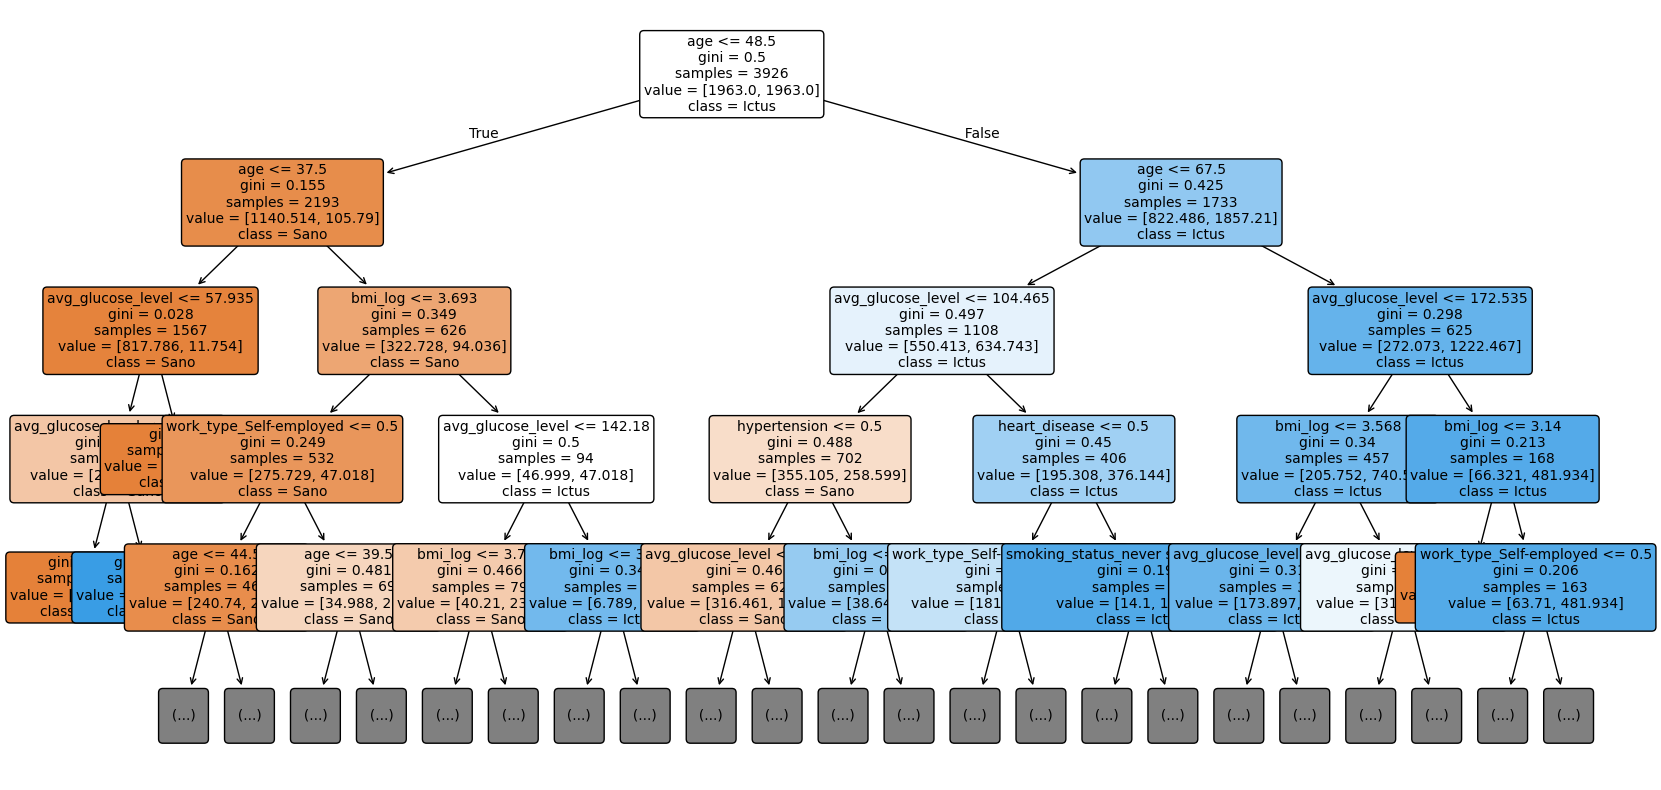

|--- age <= 48.50
|   |--- age <= 37.50
|   |   |--- avg_glucose_level <= 57.93
|   |   |   |--- avg_glucose_level <= 57.92
|   |   |   |   |--- class: 0
|   |   |   |--- avg_glucose_level >  57.92
|   |   |   |   |--- class: 1
|   |   |--- avg_glucose_level >  57.93
|   |   |   |--- class: 0
|   |--- age >  37.50
|   |   |--- bmi_log <= 3.69
|   |   |   |--- work_type_Self-employed <= 0.50
|   |   |   |   |--- age <= 44.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- age >  44.50
|   |   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- work_type_Self-employed >  0.50
|   |   |   |   |--- age <= 39.50
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- age >  39.50
|   |   |   |   |   |--- class: 0
|   |   |--- bmi_log >  3.69
|   |   |   |--- avg_glucose_level <= 142.18
|   |   |   |   |--- bmi_log <= 3.74
|   |   |   |   |   |--- truncated branch of depth 7
|   |   |   |   |--- bmi_log >  3.74
|   |   |   |   |   |--- class: 0
|   |   |   

In [18]:
class_names = ['Sano', 'Ictus']
plt.figure(figsize=(20, 10))
plot_tree(best_tree, feature_names=feature_names, class_names=class_names,
          filled=True, rounded=True, fontsize=10, max_depth=4)
plt.savefig('decision_tree.png', dpi=300, bbox_inches='tight')
plt.show()

# Representación en texto
print(export_text(best_tree, feature_names=feature_names, max_depth=4))

Tanto en la representación de texto como en el gráfico, se observa que la variable utilizada en el nodo raíz es la edad, concretamente realizando el corte en age <= 48.50. Esto significa que el modelo ha determinado que la edad es la característica que proporciona la mayor ganancia de información para realizar la primera gran división entre los pacientes del dataset. Si miramos las siguientes ramas, el árbol vuelve a dividir por age y luego utiliza las otras variables clave (avg_glucose_level y bmi_log) para encontrar perfiles de riesgo.

A nivel superficial las 4 primeras profundidades son claras y con condiciones sencillas, pero el árbol a nivel completo no es interpretable, ya que por debajo de las reglas más generales que hemos visto en la visualización, el árbol sigue haciendo decenas de preguntas minúsculas y complejas para clasificar casos aislados que no podemos observar en la propia salida.

#### 2.8 Evaluación Final (Parte 2)

Para la poda posterior utilizamos alpha=0.00033, que reduce 100 hojas manteniendo un buen accuracy (pese a que la accuracy más alta sea con alpha=0).

In [19]:
modelos_tree = {
    'Árbol Baseline (Sin Restricciones)': DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    'Árbol Poda Previa (GridSearch)': grid_tree.best_estimator_,
    'Árbol Poda Posterior (CCP alpha=0.00033)': DecisionTreeClassifier(ccp_alpha=0.00033, random_state=42, class_weight='balanced') 
}

resultados_resumen_tree = []

for nombre, modelo in modelos_tree.items():

    cv_scores = cross_val_score(modelo, X_train, y_train, cv=5)
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    test_acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    n_hojas = modelo.get_n_leaves() 
    profundidad = modelo.get_depth()
    
    resultados_resumen_tree.append({
        'Modelo': nombre,
        'CV Accuracy': round(cv_scores.mean(), 4),
        'Test Accuracy': round(test_acc, 4),
        'F1-Score': round(f1, 4),
        'Profundidad': profundidad,
        'N° Hojas': n_hojas
    })

df_resumen_tree = pd.DataFrame(resultados_resumen_tree)
df_resumen_tree

,Modelo,CV Accuracy,Test Accuracy,F1-Score,Profundidad,N° Hojas
0,Árbol Baseline (Sin Restricciones),0.9277,0.9104,0.9165,23,322
1,Árbol Poda Previa (GridSearch),0.9277,0.9104,0.9165,23,322
2,Árbol Poda Posterior (CCP alpha=0.00033),0.9165,0.8982,0.9113,23,215


Como ya hemos comentado anteriormente, para nuestro dataset y problema, el árbol sin restricciones ofrece el mejor rendimiento al no imponer ningún límite al crecimiento del árbol. Sin embargo, desde una perspectiva de equilibrio entre rendimiento y complejidad, la Poda Posterior (Cost-Complexity Pruning con alpha=0.00033) es la mejor estrategia. Mientras que el árbol sin restricciones y el de poda previa (con las condiciones sin limitar) construyen modelos muy grandes y sobreajustados (más de 300 hojas), el CCP elimina cerca de 100 hojas de la estructura. Al hacerlo, su F1-Score se reduce muy poco (de 0.9165 a 0.9113).

Comparándolo con SVM, el árbol de decisión es competitivo en accuracy y en F1-Score. Si observamos el accuracy, ambos modelos están muy parejos (SVM RBF alcanza 0.9398 y el mejor árbol ronda el 0.9104). Por otro lado, en la métrica clave para datos desbalanceados (F1-Score), el SVM RBF nos da 0.9243 mientras que los árboles de decisión oscilan entre 0.89 y 0.91. 

Por otra parte, una de las ventajas que sí que tienen los árboles de decisión respecto a SVM es su interpretabilidad. El SVM con kernel RBF proyecta los datos del paciente a dimensiones infinitas para separarlos. Si el modelo predice que un paciente va a tener un ictus, es imposible explicarle a un médico por qué el modelo ha tomado esa decisión. Por el contrario, el árbol de decisión es completamente transparente, y podemos extraer las reglas exactas que le llevan a tomar decisiones, permitiendo generarnos un ranking de la importancia de las características, aspectos muy a tener en cuenta a la hora de seleccionar uno u otro método.

##### Matriz de confusión

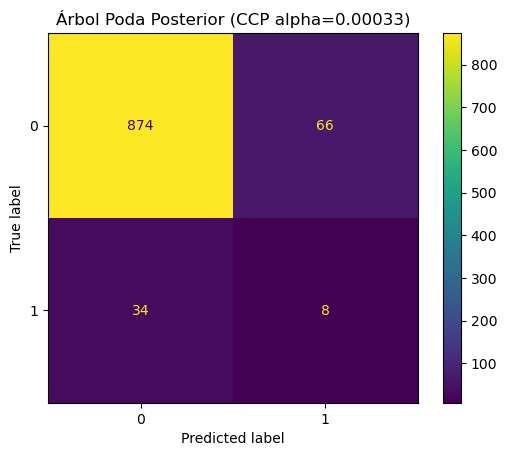

In [20]:
best_tree = modelos_tree['Árbol Poda Posterior (CCP alpha=0.00033)']
y_pred_tree = best_tree.predict(X_test)

cm = confusion_matrix(y_test, y_pred_tree)
ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.title(f'Árbol Poda Posterior (CCP alpha=0.00033)')
plt.savefig('confusion_matrix_tree.png', dpi=300, bbox_inches='tight')
plt.show()

## Parte 3: Random Forest

#### 3.1 Random Forest con Configuración por Defecto

In [21]:
start_time = time()

rf_base = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, oob_score=True, class_weight='balanced')
rf_base.fit(X_train, y_train)
y_pred_rf = rf_base.predict(X_test)

tiempo_total = time() - start_time

test_accuracy_rf = accuracy_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf, average='weighted', zero_division=0)

resultados_rf = {
    'Configuración': 'RF por defecto (n=100)',
    'OOB Score': round(rf_base.oob_score_, 4),
    'Test Accuracy': round(test_accuracy_rf, 4),
    'F1-Score': round(f1_rf, 4)
}

print(f'Tiempo(s): {tiempo_total:.4f}')

df_rf = pd.DataFrame([resultados_rf])
df_rf

Tiempo(s): 0.5462


,Configuración,OOB Score,Test Accuracy,F1-Score
0,RF por defecto (n=100),0.9562,0.9562,0.9358


Como podemos observar en la tabla, el OOB Score (0.9562) ha coincidido exactamente con el Test Accuracy (0.9562), lo que nos indica que OOB Score es una estimación excepcional. Además, estos resultados nos indican que ya usando la configuración por defecto, el random forest nos ofrece mejores resultados que el árbol de decisión individual, mejorando cerca de un 4% los valores de Test Accuracy y F1-Score. Esto se debe a que, mientras que el árbol individual es propenso a sobreajustarse debido al ruido, el random forest entrena 100 árboles diferentes y promedia sus predicciones, cancelando de esta manera los errores individuales de cada uno de ellos.

#### 3.2 Efecto del Número de Estimadores

In [22]:
resultados_rf_n = []

for n in [10, 25, 50, 100, 200, 500]:
    start_time = time()

    rf = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1, oob_score=True, class_weight='balanced')
    rf.fit(X_train, y_train)

    test_acc = rf.score(X_test, y_test)

    end_time = time()
    tiempo_total = end_time - start_time
    
    resultados_rf_n.append({
        'n_estimators': n,
        'OOB Score': round(rf.oob_score_, 4),
        'Test Accuracy': round(test_acc, 4),
        'Tiempo (s)': round(tiempo_total, 4)
    })

df_rf_n = pd.DataFrame(resultados_rf_n)
df_rf_n

c:\Users\pepov\anaconda\envs\Aprendizaje_AV\Lib\site-packages\sklearn\ensemble\_forest.py:611: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


,n_estimators,OOB Score,Test Accuracy,Tiempo (s)
0,10,0.9508,0.9532,0.0788
1,25,0.9557,0.9532,0.1111
2,50,0.9572,0.9542,0.2133
3,100,0.9562,0.9562,0.3607
4,200,0.9567,0.9552,0.7307
5,500,0.9564,0.9562,1.5023


Al variar el número de estimadores, observamos que el rendimiento se estabiliza a partir de los 50/100 árboles, donde se llega a sus picos más altos tanto de OOB score como de test accuracy, pese a que en todos los ejemplos los cambios son muy pequeños de unos a otros. Siendo muy significativa la no mejora de rendimiento de 100 a 500 árboles, donde, como ya he comentado, se estabilizan los valores y no supone ningún cambio a mejor aumentar más el número de estimadores. Sin embargo, lo que si que podemos observar como una diferencia notable son los valores de los tiempos de ejecución, donde esta nula mejora que hemos comentado está totalmente desproporcionada con el coste computacional del uso de esa cantidad de estimadores. El tiempo de ejecución se dispara de forma lineal, al entrenar 100 árboles se tardan 0.297 segundos, mientras que entrenar 500 dura 1.453 segundos, por lo que podemos concluir que el punto óptimo del uso de árboles estaría rondando una configuración con 100 de ellos.

#### 3.3 Efecto de max_features

In [23]:
resultados_rf_mf = []

for mf in ['sqrt', 'log2', 0.5, None]:
    start_time = time()

    rf = RandomForestClassifier(n_estimators=100, max_features=mf,
                                random_state=42, n_jobs=-1, oob_score=True, class_weight='balanced')
    rf.fit(X_train, y_train)
    test_acc = rf.score(X_test, y_test)

    end_time = time()
    tiempo_total = end_time - start_time

    resultados_rf_mf.append({
        'max_features': mf,
        'OOB Score': round(rf.oob_score_, 4),
        'Test Accuracy': round(test_acc, 4),
        'Tiempo (s)': round(tiempo_total, 4)
    })

df_rf_mf = pd.DataFrame(resultados_rf_mf)
df_rf_mf

,max_features,OOB Score,Test Accuracy,Tiempo (s)
0,sqrt,0.9562,0.9562,0.4037
1,log2,0.9562,0.9562,0.3501
2,0.5,0.9570,0.9562,0.3882
3,None,0.9547,0.9552,0.4325


Al reducir max_features, estamos obligando a cada árbol a mirar solo a un subconjunto aleatorio de variables, por lo que se están generando árboles muy diferentes entre sí y favorece la diversidad del ensemble. En cuanto al rendimiento, las diferencias entre unas y otras restricciones son mínimas, pero la más lejana es la opción en la que no se establece ninguna restricción, por lo que diríamos que reducir max_features también mejora el rendimiento.

Como hemos visto en la sección de Árboles de Decisión, variables como la edad son excesivamente dominantes. Si dejamos max_features=None, todos los árboles van a tener acceso a la edad en su primer nodo, y prácticamente los 100 árboles van a hacer la misma división inicial. Esto provoca que el bosque esté lleno de árboles altamente correlacionados, yendo en contra de lo que incita el random forest.

En cuanto a nuestro dataset, el valor óptimo es 0.5, que nos da ligeramente mejores resultados que el resto (log2 se queda muy cerca) tanto en OOB Score (0.9570) como en el tiempo de ejecución (0.3378s).

#### 3.4 Grid Search

In [30]:
param_grid = {
    'n_estimators':     [100, 200],
    'max_features':     ['sqrt', 'log2', None],
    'max_depth':        [None, 10, 20],
    'min_samples_leaf': [1, 2, 5]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1, class_weight='balanced', oob_score=True),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print(f"Mejores parámetros: {grid_rf.best_params_}")
print(f"Mejor CV score:     {grid_rf.best_score_:.4f}")
print(f"Test score:         {grid_rf.best_estimator_.score(X_test, y_test):.4f}")

Mejores parámetros: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}
Mejor CV score:     0.9580
Test score:         0.9552


Al realizar el grid search con la cross validation, obtenemos los parámetros que nos dan los resultados más estables:
- max_depth = 20
- max_features = sqrt
- min_samples_leaf = 1
- n_estimators = 200

#### 3.5 Importancia de Características

In [25]:
best_rf = grid_rf.best_estimator_

# Gini Importance (MDI)
importances_gini = best_rf.feature_importances_

# Permutation Importance (más fiable con features correlacionadas)
perm = permutation_importance(best_rf, X_test, y_test, n_repeats=10, random_state=42)

resultados_importancia = []

indices = importances_gini.argsort()[::-1]
for i, idx in enumerate(indices):
    perm_importance = f"{perm.importances_mean[idx]:.4f} (+/- {perm.importances_std[idx]:.4f})"
    
    resultados_importancia.append({
        'Ranking': i + 1,
        'Feature': feature_names[idx],
        'Gini Importance': round(importances_gini[idx], 4),
        'Permutation Importance': perm_importance
    })

df_importancia_rf = pd.DataFrame(resultados_importancia)
df_importancia_rf

,Ranking,Feature,Gini Importance,Permutation Importance
0,1,age,0.3747,-0.0017 (+/- 0.0007)
1,2,avg_glucose_level,0.2090,-0.0013 (+/- 0.0007)
2,3,bmi_log,0.1630,-0.0017 (+/- 0.0005)
3,4,hypertension,0.0506,-0.0010 (+/- 0.0000)
4,5,ever_married,0.0281,0.0003 (+/- 0.0008)
5,6,gender,0.0240,-0.0005 (+/- 0.0005)
6,7,Residence_type,0.0231,0.0004 (+/- 0.0010)
7,8,heart_disease,0.0228,-0.0010 (+/- 0.0000)
8,9,smoking_status_never smoked,0.0204,-0.0011 (+/- 0.0008)
9,10,work_type_Self-employed,0.0196,-0.0005 (+/- 0.0008)


Según el Gini Importance, hay tres variables indiscutibles que dominan el modelo: la edad (age con 0.3747), el nivel de glucosa (avg_glucose_level con 0.2090) y el índice de masa corporal (bmi_log con 0.1630). Sin embargo, para Permutation Importance las variables que el Gini consideraba cruciales tienen valores de permutación negativos (como age = -0.0017), lo que indica que desordenar esa columna en el set de validación no empeoró el rendimiento del modelo. Curiosamente, variables demográficas menores como ever_married (0.0003) o Residence_type (0.0004) son los que aparecen como valores positivos. Esta diferencia entre el Gini y la Permutation se puede deber a que el Permutation Importance castiga duramente a las variables correlacionadas, ya que al utilizar Random Forests el modelo tiene alternativas para llegar a la misma conclusión con unas características o con otras, pudiendo darle menos importancia a las variables con mayor peso en caso necesario y haciendo que la importancia de permutación de la variable individual sea nula.

Las features más importantes de los Random Forest también coinciden con las analizadas en el árbol individual (en el mismo orden). A pesar de que el Random Forest introduce aleatoriedad (max_features), la fuerza estadística de la edad, la glucosa y el bmi en este dataset médico es tan importante que siguen siendo los pilares fundamentales de las decisiones clínicas del algoritmo.

#### 3.6 Extra Trees

In [26]:
start_time = time()

et = ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1, class_weight='balanced')
et.fit(X_train, y_train)
cv_et = cross_val_score(et, X_train, y_train, cv=5)
test_acc_et = et.score(X_test, y_test)
y_pred_et = et.predict(X_test)
f1_et = f1_score(y_test, y_pred_et, average='weighted', zero_division=0)

tiempo_et = time() - start_time

print(f"Extra Trees: CV={cv_et.mean():.4f} (+/-{cv_et.std():.4f}), "
      f"Test={et.score(X_test, y_test):.4f}, "
      f"F1-Score={f1_et:.4f}, "
      f"Tiempo(s)={tiempo_et:.4f}")

Extra Trees: CV=0.9547 (+/-0.0013), Test=0.9450, F1-Score=0.9302, Tiempo(s)=1.7777


Aunque Extra Trees simplifica el cálculo matemático al elegir divisiones aleatorias (lo que teóricamente lo hace más rápido), en este dataset empeora ligeramente el rendimiento respecto al Random Forest, reduciendo el Test Accuracy a 0.9450 y el F1-Score a 0.9302. Esta caída de precisión evidencia que introducir un nivel tan extremo de aleatoriedad genera un sesgo excesivo para este problema. Dado que la detección del ictus depende críticamente de encontrar umbrales exactos en variables continuas muy dominantes (como la edad o los niveles de glucosa), realizar cortes al azar reduce su impacto en las predicciones.

#### 3.7 Evaluación Final (Parte 3)

In [31]:
modelos_finales = {
    'Decision Tree (baseline)': tree_full,
    'Random Forest por defecto': rf_base,
    'Random Forest mejor config': grid_rf.best_estimator_,
    'Extra Trees': et
}

resultados_finales = []

for nombre, modelo in modelos_finales.items():
    
    start_time = time()
    
    cv_scores = cross_val_score(modelo, X_train, y_train, cv=5)
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    
    tiempo_total = time() - start_time

    test_acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    if 'Random Forest' in nombre:
        oob = round(modelo.oob_score_, 4)
    else:
        oob = 'N/A'
        
    resultados_finales.append({
        'Modelo': nombre,
        'CV Accuracy': round(cv_scores.mean(), 4),
        'Test Accuracy': round(test_acc, 4),
        'F1-Score': round(f1, 4),
        'OOB Score': oob,
        'Tiempo (s)': round(tiempo_total, 4)
    })

df_resultados_finales = pd.DataFrame(resultados_finales)
df_resultados_finales

,Modelo,CV Accuracy,Test Accuracy,F1-Score,OOB Score,Tiempo (s)
0,Decision Tree (baseline),0.9277,0.9104,0.9165,N/A,0.1208
1,Random Forest por defecto,0.9577,0.9562,0.9358,0.9562,2.9608
2,Random Forest mejor config,0.9580,0.9552,0.9353,0.9564,4.8407
3,Extra Trees,0.9547,0.9450,0.9302,N/A,1.8351


El paso de un árbol de decisión individual a un ensemble (Random Forest) supone una mejora muy significativa en el rendimiento, elevando el Test Accuracy de un 0.9104 a un sobresaliente 0.9562, y el F1-Score de 0.9165 a 0.9358. Esta gran evolución demuestra la principal ventaja teórica de los ensembles, que al combinar las predicciones de 100 árboles distintos, el Random Forest logra cancelar el sobreajuste y la alta varianza del modelo individual, generando una herramienta mucho más robusta y fiable.

A pesar del proceso de búsqueda de una combinación lo más acertada posible, la configuración óptima obtenida mediante GridSearch no logra superar a los valores por defecto en términos de rendimiento final sobre datos no vistos. De hecho, el modelo por defecto consigue unas métricas un poco superiores en el set de prueba (con un Accuracy de 0.9562 frente a 0.9552, y un F1-Score de 0.9358 frente a 0.9353), lo que evidencia que la pequeña ventaja teórica de la configuración óptima durante la validación cruzada (0.9580 vs 0.9577) no se ha convertido en una mayor capacidad de generalización.

Como consecuencia, el coste computacional extra del tuning no vale la pena para nuestro caso concreto. La configuración óptima requiere casi el doble de tiempo de entrenamiento (5.26 segundos frente a los 2.99 del modelo por defecto), además del tiempo previo invertido por el GridSearch en evaluar todas las combinaciones posibles, para finalmente no obtener ningún beneficio de predicción en el test. Estos resultados demuestran que los Random Forests son capaces de ofrecer su máximo rendimiento sin necesidad de un ajuste exhaustivo de hiperparámetros.

##### Matriz de confusión

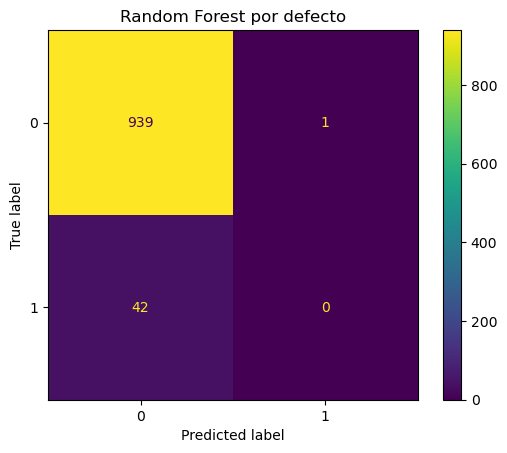

In [32]:
best_rf_final = modelos_finales['Random Forest por defecto']
y_pred_rf_final = best_rf_final.predict(X_test)

cm = confusion_matrix(y_test, y_pred_rf_final)
ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.title(f'Random Forest por defecto')
plt.savefig('confusion_matrix_rf.png', dpi=300, bbox_inches='tight')
plt.show()

A pesar de que el Random Forest logra el mejor Test Accuracy global (95.6%), el análisis de su matriz de confusión revela un comportamiento que ya habíamos visto en la práctica anterior antes de realizar el balanceo de clases. Aquí, el modelo colapsa ante la clase mayoritaria y predice 'Sano' de forma casi sistemática (detectando solo 1 caso de ictus frente a los 42 reales omitidos). Este comportamiento contrasta fuertemente con los modelos SVM y Árbol de Decisión, los cuales, usando el mismo parámetro de balanceo de clases, sí lograron detectar una porción significativa de pacientes de riesgo (pese a tener sus fallos en las predicciones).

Este fenómeno tiene como causa la estructura del Random Forest. Cada uno de los 100 árboles del bosque se entrena con una submuestra aleatoria de los datos de entrenamiento, y como hay tan pocos casos de ictus en el dataset (<5%), estadísticamente es muy probable que a muchos de esos 100 árboles les toque una muestra sin casi ningún paciente con ictus. Esto se vuelve un problema cuando llega la hora de predecir por medio del Random Forest, ya que a diferencia de SVM y los árboles donde las reglas que definen el riesgo de ictus prevalecen, aquí los 100 árboles seleccionados votan equitativamente para seleccionar el diagnóstico, por lo que el voto por mayoría en clases desbalanceadas tiende a aplastar a la clase minoritaria, diluyendo el efecto del class_weight.

Una posible solución a este problema de las predicciones puede ser reducir el umbral de decisión de los random forest para que no sea necesario que la clase indicada supere el 50% de los votos de los árboles, proponiendo una reducción al 15% o 20% para prevenir y dar diagnósticos más seguros.

##### Matriz de confusión aplicando un umbral del 15%

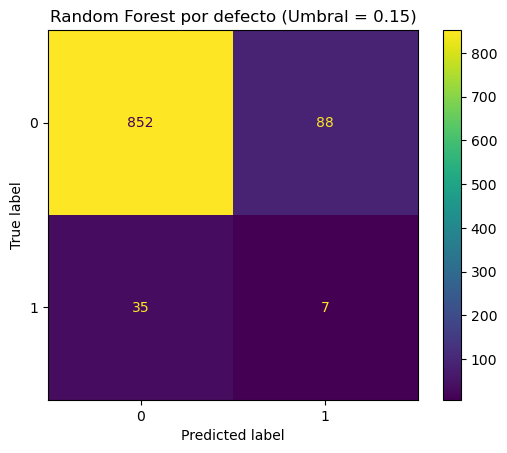

In [33]:
best_rf_final = modelos_finales['Random Forest por defecto']

# [:, 1] coge solo la columna de las probabilidades de tener ictus (Clase 1) en vez de la predicción final
y_probs = best_rf_final.predict_proba(X_test)[:, 1]

# Si la probabilidad es mayor o igual a 0.15, será 1 (Ictus), si no, 0 (Sano)
umbral = 0.15
y_pred_custom = (y_probs >= umbral).astype(int)

cm_custom = confusion_matrix(y_test, y_pred_custom)
ConfusionMatrixDisplay(confusion_matrix=cm_custom).plot()
plt.title(f'Random Forest por defecto (Umbral = {umbral})')
plt.savefig('confusion_matrix_rf_custom.png', dpi=300, bbox_inches='tight')
plt.show()

Aplicando este umbral, podemos ver que ahora el modelo sí que detecta más personas con riesgo de ictus, pese a que sigue dejando a 35 pacientes con riesgo real sin predecir (al igual que con el resto de modelos vistos de momento en esta práctica) y aumenta principalmente los falsos positivos de manera preventiva.

## Parte 4: Gradient Boosting

A diferencia del resto de apartados, en Gradient Boosting no puedo pasar como parámetro el balanceo de clases, por lo que va a sufrir el mismo problema que hemos tenido en el Random Forest, el modelo va a predecir que casi todos los pacientes están sanos para asegurar un Accuracy alto. Sin embargo, con sklearn podemos introducir compute_sample_weight para calcular de manera manual los pesos y pasarlos como parámetros de entrenamiento, de esta manera, nos aseguramos que el Gradient Boosting deje de ignorar a la clase minoritaria.

#### 4.1 Gradient Boosting con Configuración por Defecto

In [34]:
pesos_train = compute_sample_weight(class_weight='balanced', y=y_train)

start_time = time()

gb_base = GradientBoostingClassifier(random_state=42)
gb_base.fit(X_train, y_train, sample_weight=pesos_train)
cv_gb = cross_val_score(gb_base, X_train, y_train, cv=5, params={'sample_weight': pesos_train})

y_pred_gb = gb_base.predict(X_test)
tiempo_total = time() - start_time

f1_gb = f1_score(y_test, y_pred_gb, average='weighted', zero_division=0)

print(f"CV={cv_gb.mean():.4f} (+/-{cv_gb.std():.4f}), "
      f"Test={gb_base.score(X_test, y_test):.4f}, "
      f"F1-Score={f1_gb:.4f}, "
      f"Tiempo(s)={tiempo_total:.4f}")

CV=0.8225 (+/-0.0144), Test=0.7953, F1-Score=0.8530, Tiempo(s)=4.2290


Los resultados del Gradient Boosting son bastante peores que el Random Forest por defecto, debido al balanceo de clases que no captan los RF (por lo que son resultados sesgados y que no debemos tener al 100% en cuenta), tanto en accuracy (0.7953 frente a 0.9562) como en F1-Score (0.8530 frente a 0.9358). Además, su entrenamiento es notablemente más lento. Al contrario que el Random Forest (Tiempo(s): 0.5936), que es paralelizable y puede plantar todos sus árboles a la vez, el Gradient Boosting (Tiempo(s)=4.5601) es estrictamente secuencial y debe construir cada árbol uno por uno. A pesar de este mayor coste computacional, puede llegar a ser un punto de partida prometedor para la optimización, ya que con esta configuración por defecto los resultados no son malos (principalmente F1-Score), afinar sus hiperparámetros y aplicar un ajuste del umbral de decisión lo puede convertir en un buen candidato.

#### 4.2 Efecto del Número de Estimadores y Learning Rate

In [35]:
configs = [
    (50,  0.1), (100, 0.1), (200, 0.1),
    (50,  0.5), (100, 0.05), (200, 0.01)
]

resultados_gb = []

pesos_train = compute_sample_weight(class_weight='balanced', y=y_train)

for n_est, lr in configs:
    gb = GradientBoostingClassifier(n_estimators=n_est, learning_rate=lr, random_state=42)
    cv = cross_val_score(gb, X_train, y_train, cv=5, params={'sample_weight': pesos_train})
    gb.fit(X_train, y_train, sample_weight=pesos_train)
    test_acc = gb.score(X_test, y_test, )

    resultados_gb.append({
        'n_estimators': n_est,  
        'learning_rate': lr,
        'CV Accuracy': round(cv.mean(), 4),
        'Test Accuracy': round(test_acc, 4)
    })

df_gb = pd.DataFrame(resultados_gb)
df_gb

,n_estimators,learning_rate,CV Accuracy,Test Accuracy
0,50,0.10,0.7955,0.7648
1,100,0.10,0.8225,0.7953
2,200,0.10,0.8591,0.8269
3,50,0.50,0.8777,0.8452
4,100,0.05,0.7939,0.7648
5,200,0.01,0.7481,0.7393


Analizando la relación entre el número de estimadores y learning rate, observamos que al reducir el learning rate a la mitad (de 0.1 a 0.05), hemos necesitado exactamente el doble de estimadores (de 50 a 100) para alcanzar exactamente el mismo rendimiento (0.7648 en test accuracy), demostrando la relación inversa de estos dos parámetros. 

En la tabla, el caso con el learning rate más alto es el de (50, 0.50), que es el que mejor rendimiento da en Test (0.8452), pero si miramos la diferencia con el CV (0.8777), vemos una caída de 3.25 puntos. Aunque es el mejor modelo de la tabla, es el que presenta una mayor brecha entre entrenamiento y prueba. Podemos analizar entonces que un learning rate alto hace que el modelo dé saltos muy grandes para corregir errores, pero el riesgo es que con pocos estimadores, esos saltos sean tan bruscos que el modelo acabe memorizando ruidos específicos del conjunto de entrenamiento en lugar de tendencias generales.

Por otra parte, para casos con un learning rate muy bajo y con muchos estimadores, podemos ver que el modelo se satura (underfitting), como en el ejemplo con 200 estimadores y un 0.01 de learning rate, donde obtenermos el resultado más bajo de todo el análisis (0.7393).

#### 4.3 Efecto de max_depth

In [36]:
pesos_train = compute_sample_weight(class_weight='balanced', y=y_train)
resultados = []

for depth in [1, 2, 3, 5]:
    gb = GradientBoostingClassifier(max_depth=depth, n_estimators=100, learning_rate=0.1, random_state=42)
    cv = cross_val_score(gb, X_train, y_train, cv=5, params={'sample_weight': pesos_train})
    gb.fit(X_train, y_train, sample_weight=pesos_train)
    
    resultados.append({
        'max_depth': depth,
        'Train Acc': round(gb.score(X_train, y_train), 4),
        'CV Accuracy': round(cv.mean(), 4),
        'Test Accuracy': round(gb.score(X_test, y_test), 4)
    })

df_depth = pd.DataFrame(resultados)
df_depth

,max_depth,Train Acc,CV Accuracy,Test Accuracy
0,1,0.7354,0.7292,0.7200
1,2,0.7837,0.7804,0.7597
2,3,0.8523,0.8225,0.7953
3,5,0.9475,0.9040,0.8707


Observando el efecto de max_depth, cuanto más se le permite al algoritmo profundizar mejores resultados saca. Sin embargo, la diferencia entre el train accuracy y el test es grandísima utilizando esta limitación (casi 8% de diferencia), mientras que cuanto menos profundidad máxima apliquemos menor será la diferencia entre una métrica y otra, a costa de recibir resultados menores. Para encontrar el punto óptimo nos tendríamos que quedar en un balance intermedio, donde árboles más simples con profundidades como 2 o 3 generalizan mejor y aún así evitan el ruido. A diferencia de los Random Forests que crean árboles muy profundos para ser lo más precisos posible por sí solos, en Gradient Boosting estos árboles más simples que hemos comentado va aprendiendo poco a poco de una manera secuencial, por lo que aplicar mucha profundidad al inicio del entrenamiento haría que el modelo aprendiese demasiado en los primeros pasos y no tendría prácticamente capacidad de mejora con los siguientes árboles.

#### 4.4 Grid Search

In [37]:
pesos_train = compute_sample_weight(class_weight='balanced', y=y_train)

param_grid = {
    'n_estimators':  [100, 200],
    'learning_rate': [0.01, 0.05, 0.1, 0.5],
    'max_depth':      [1, 2, 3],
    'subsample':      [0.8, 1.0]
}

grid_gb = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_gb.fit(X_train, y_train, sample_weight=pesos_train)

print(f"Mejores parámetros: {grid_gb.best_params_}")
print(f"Mejor CV score:     {grid_gb.best_score_:.4f}")
print(f"Test score:         {grid_gb.best_estimator_.score(X_test, y_test):.4f}")

Mejores parámetros: {'learning_rate': 0.1, 'max_depth': 1, 'n_estimators': 200, 'subsample': 0.8}
Mejor CV score:     0.7795
Test score:         0.7403


Al realizar el grid search con la cross validation, obtenemos los parámetros que nos dan los resultados más estables:
- learning_rate = 0.1
- max_depth = 1
- n_estimators = 200
- subsample = 0.8

#### 4.5 AdaBoost

In [38]:
pesos_train = compute_sample_weight(class_weight='balanced', y=y_train)

configs = [
    (50, 1.0),
    (100, 1.0),
    (100, 0.5),
    (200, 0.1)
]

resultados_ada = []

for n, lr in configs:
    # AdaBoost con árbol de decisión de profundidad 1 (stump) como estimador base
    ada = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=n,
        learning_rate=lr,
        random_state=42
    )
    
    cv = cross_val_score(ada, X_train, y_train, cv=5, params={'sample_weight': pesos_train})
    ada.fit(X_train, y_train, sample_weight=pesos_train)
    
    resultados_ada.append({
        'n_estimators': n,
        'learning_rate': lr,
        'CV Accuracy': round(cv.mean(), 4),
        'Test Accuracy': round(ada.score(X_test, y_test), 4)
    })

df_ada = pd.DataFrame(resultados_ada)
df_ada

,n_estimators,learning_rate,CV Accuracy,Test Accuracy
0,50,1.0,0.7669,0.7525
1,100,1.0,0.7356,0.6955
2,100,0.5,0.6783,0.7047
3,200,0.1,0.6717,0.6762


Al comparar los resultados, observamos que AdaBoost es menos competitivo que Gradient Boosting. Mientras que GB lograba alcanzar precisiones en Test por encima del 80% en sus mejores configuraciones balanceadas, AdaBoost se queda atrás sobre el 70-75%. Un aspecto a comentar sobre esta diferencia viene siendo también la diferencia de comportamiento de estos dos métodos. En AdaBoost, se utiliza una ponderación de muestras donde cada vez que el árbol falla, se aumenta el peso de los pacientes mal clasificados de cara al siguiente árbol, mientras que Gradient Boosting funciona mediante el ajuste de residuos, donde cada árbol intenta predecir el error del modelo anterior.

Observando el comportamiento de la variación de parámetros en AdaBoost, se observa una saturación muy temprana e incluso una degradación del rendimiento, como al aumentar el número de estimadores a 100 manteniendo el learning rate igual, obteniendo una caída del accuracy del 0.7525 al 0.6955, indicandonos que para este modelo añadir más árboles no siempre es mejor.

#### 4.6 Evaluación Final (Parte 4)

In [39]:
# Asegúrate de que 'gb' sea tu modelo base (n=100, lr=0.1) y 'ada' sea tu mejor AdaBoost
modelos_finales = {
    'Random Forest (mejor config)': grid_rf.best_estimator_,
    'Gradient Boosting por defecto': gb_base,
    'Gradient Boosting mejor config': grid_gb.best_estimator_,
    'AdaBoost': AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), 
                                   n_estimators=50, learning_rate=1.0, random_state=42) # Configuración óptima de AdaBoost
}

resultados_finales = []

for nombre, modelo in modelos_finales.items():
    start_time = time()
    
    cv_scores = cross_val_score(modelo, X_train, y_train, cv=5, params={'sample_weight': pesos_train})
    modelo.fit(X_train, y_train, sample_weight=pesos_train)
    
    y_pred = modelo.predict(X_test)
    tiempo_total = time() - start_time

    resultados_finales.append({
        'Modelo': nombre,
        'CV Accuracy': round(cv_scores.mean(), 4),
        'Test Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred, average='weighted', zero_division=0), 4),
        'Tiempo (s)': round(tiempo_total, 4)
    })

df_final = pd.DataFrame(resultados_finales)
df_final

,Modelo,CV Accuracy,Test Accuracy,F1-Score,Tiempo (s)
0,Random Forest (mejor config),0.9564,0.9542,0.9348,6.7146
1,Gradient Boosting por defecto,0.8225,0.7953,0.8530,3.3847
2,Gradient Boosting mejor config,0.7481,0.7403,0.8174,4.1354
3,AdaBoost,0.7669,0.7525,0.8254,4.0634


Aunque el RF muestra un Accuracy del 95.42%, como bien hemos analizado, este resultado está sesgado: el modelo se ha limitado a memorizar la clase mayoritaria, siendo inútil para la detección clínica de ictus. En cambio, el Gradient Boosting (en su versión por defecto) ha sido capaz de utilizar los pesos balanceados para aprender patrones reales y se alza como el modelo más robusto y útil del análisis, con un Test Accuracy del 79.53% y un F1-Score de 0.8530. Por otra parte, la diferencia en tiempo de ejecución es mínima: el Random Forest tarda 3.13 segundos frente a los 3.64 - 3.86 segundos del Gradient Boosting, una diferencia de apenas 0.5 - 0.7 segundos respectivamente. 

Comparando directamente las dos versiones del Gradient Boosting, observamos que su modelo por defecto ya es lo suficientemente bueno y que no hay una mejora posible tras hacer la búsqueda de hiperparámetros, ya que para evitar el overfitting el GridSearchCV selecciona parámetros muy conservadores, a diferencia del modelo base que al tener más profundidad arriesga un poco más y obtiene resultados mejores en datos no vistos, quedando un 0.8225 vs 0.7481 en CV Accuracy, un 0.7953 vs 0.7403 en Test Accuracy y un 0.8530 vs 0.8174 en F1-Score.

Por último, la comparación con AdaBoost lo muestra como un modelo competitivo con el resto, pero que se queda un paso por detrás del ganador que es el GB. Con un Test Accuracy del 75.25%, supera ligeramente a la "mejor configuración" encontrada por el GridSearch de GB (74.03%), pero no logra alcanzar el 79.53% del GB por defecto. Un aspecto a favor de este modelo es que es el más rápido en relizar la ejecución de todos los comparados (2.93s).

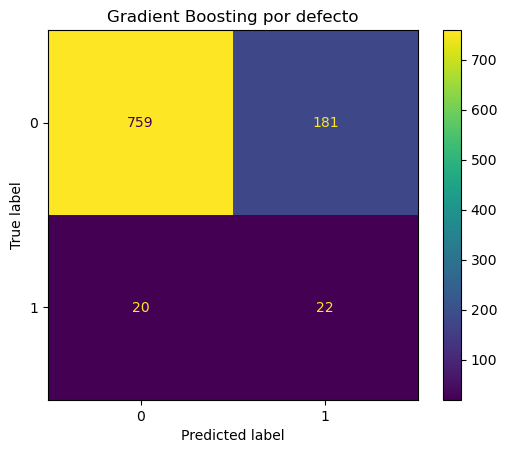

In [40]:
best_gb_final = modelos_finales['Gradient Boosting por defecto']
y_pred_gb_final = best_gb_final.predict(X_test)

cm = confusion_matrix(y_test, y_pred_gb_final)
ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.title(f'Gradient Boosting por defecto')
plt.savefig('confusion_matrix_gb.png', dpi=300, bbox_inches='tight')
plt.show()

Con el uso de este modelo, conseguimos la mayor cantidad de pacientes con riesgo de ictus detectados correctamente. Más del 50% de los pacientes con riesgo real han sido detectados (22), mientras que se han lanzado 181 falsos positivos a modo de prevención. Esto en términos médicos es un claro avance, ya que es preferible aumentar los posibles perfiles de riesgo aunque no sean seguros, con tal de poder actuar a tiempo en casos reales donde si que sea crítica la detección del riesgo.

## Parte Final: Comparación y Evaluación Global

In [44]:
pesos_train = compute_sample_weight(class_weight='balanced', y=y_train)

decision_tree = DecisionTreeClassifier(ccp_alpha=0.00033, random_state=42, class_weight='balanced')
adaboost = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=50, learning_rate=1.0, random_state=42)

best_models = {
    'SVM (mejor config)': best_svm,
    'Decision Tree': decision_tree,
    'Random Forest': rf_base,
    'Gradient Boosting': gb_base,
    'AdaBoost': adaboost
}

resultados_finales = []

for nombre, modelo in best_models.items():
    start_time = time()
    
    if nombre in ['Gradient Boosting', 'AdaBoost']:
        cv = cross_val_score(modelo, X_train, y_train, cv=5, params={'sample_weight': pesos_train})
        modelo.fit(X_train, y_train, sample_weight=pesos_train)
    else:
        cv = cross_val_score(modelo, X_train, y_train, cv=5)
        modelo.fit(X_train, y_train)
    
    y_pred = modelo.predict(X_test)
    tiempo_total = time() - start_time
    
    resultados_finales.append({
        'Modelo': nombre,
        'CV Accuracy': round(cv.mean(), 4),
        'Test Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred, zero_division=0), 4),
        'Recall': round(recall_score(y_test, y_pred, zero_division=0), 4),
        'F1-Score': round(f1_score(y_test, y_pred, average='weighted', zero_division=0), 4),
        'Tiempo (s)': round(tiempo_total, 4)
    })

df_comparativa_global = pd.DataFrame(resultados_finales)
df_comparativa_global

,Modelo,CV Accuracy,Test Accuracy,Precision,Recall,F1-Score,Tiempo (s)
0,SVM (mejor config),0.9325,0.9257,0.1026,0.0952,0.9243,1.7311
1,Decision Tree,0.9165,0.8982,0.1081,0.1905,0.9113,0.0952
2,Random Forest,0.9577,0.9562,0.0000,0.0000,0.9358,3.1630
3,Gradient Boosting,0.8225,0.7953,0.1084,0.5238,0.8530,3.3833
4,AdaBoost,0.7669,0.7525,0.1028,0.6190,0.8254,3.1820


Ya con las mejores configuraciones y las métricas completas de cada uno de los apartados, observamos un detalle muy a tener en cuenta, que es la métrica del Recall. Al estar trabajando con un dataset desbalanceado (pese a que hayamos aplicado balanceo en los modelos), no nos podemos fiar solo del accuracy y tenemos que darle más importancia al Recall para detectar la solución al problema médico. Siguiendo esta métrica, los dos modelos que destacan enormemente del resto son Gradient Boosting (0.5238) y AdaBoost (0.6190), significando que estos dos modelos son capaces de identificar correctamente a más de la mitad de los pacientes enfermos. Además, AdaBoost ofrece un gran equilibrio entre el rendimiento y el coste computacional, ofreciendo el mejor Recall en 1.89 segundos.

Si observamos el resto de modelos, tanto SVM como Decision Tree fallan casi todas las veces en este tipo de detecciones, con un único 10% de acierto en estos pacientes, demostrando que los métodos ensemble superan a los modelos individuales de forma contundente, multiplicando por tres o por seis la capacidad de detección. En el caso de Random Forest, como ya he ido comentando a lo largo de la práctica, al no poder realizar el balanceo de clases, este modelo está totalmente sesgado y es inútil para cualquier tipo de predicción, porque no mira cada paciente característica a característica sino que da un veredicto base (que el paciente está sano) para obtener buenas valoraciones en las accuracys, así que no le daremos el mismo lugar que al resto de modelos analizados.

En términos generales, existe una consistencia muy alta entre los resultados de CV y los de test. En todos los modelos, la diferencia entre la CV Accuracy y la Test Accuracy es mínima (apenas 1-2 puntos). Esto indica que los modelos no han sobreajustado fuertemente y que los resultados que estamos viendo son representativos de cómo se comportarían con pacientes nuevos.

Para este dataset, estamos viendo que es recomendable el uso de la familia de modelos Boosting (AdaBoost o Gradient Boosting), ya que en medicina, el coste de un falso negativo(decirle a alguien que está sano cuando va a sufrir un ictus) es infinitamente superior al de un falso positivo (hacer pruebas extra a alguien sano). Los modelos de Boosting son los únicos que han demostrado capacidad para aprender de la clase minoritaria bajo condiciones de desbalanceo extremo, ofreciendo un Recall que realmente permite una intervención preventiva.

#### Matriz de confusión

Como ya tenemos la matriz de confusión de Gradient Boosting en el apartado anterior, mostramos ahora la de AdaBoost basándonos en el Recall más alto.

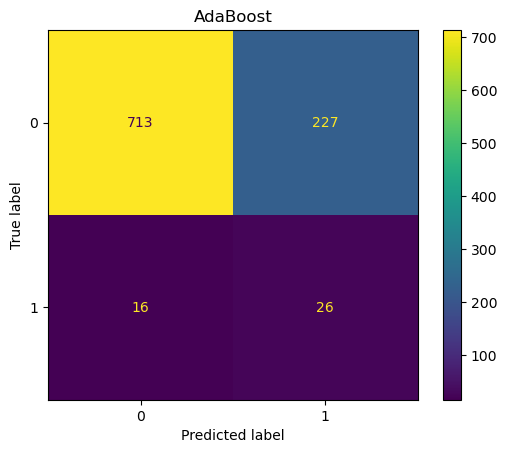

In [42]:
best_model_final = best_models['AdaBoost']
y_pred_model_final = best_model_final.predict(X_test)

cm = confusion_matrix(y_test, y_pred_model_final)
ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.title(f'AdaBoost')
plt.savefig('confusion_matrix_adaboost.png', dpi=300, bbox_inches='tight')
plt.show()

En esta matriz de confusión de AdaBoost, observamos lo que hemos razonado sobre los resultados de la tabla anterior. Este modelo logra detectar 26 de los 42 pacientes con riesgo real de ictus y lanza 227 diagnósticos de riesgo falso. El modelo tiende a ser conservador, prefiere dar una señal de alarma ante la más mínima duda diagnóstica, siendo claro el patrón, sacrificar Precision a cambio de Recall, es decir, prefiere decirle a un paciente sano que tiene riesgo de ictus y realizarle pruebas adicionales (bajo coste), que decirle a los pacientes que van a sufrir un ictus que están sanos (coste altísimo).

## Gráficas extra

#### Accuracy VS Recall

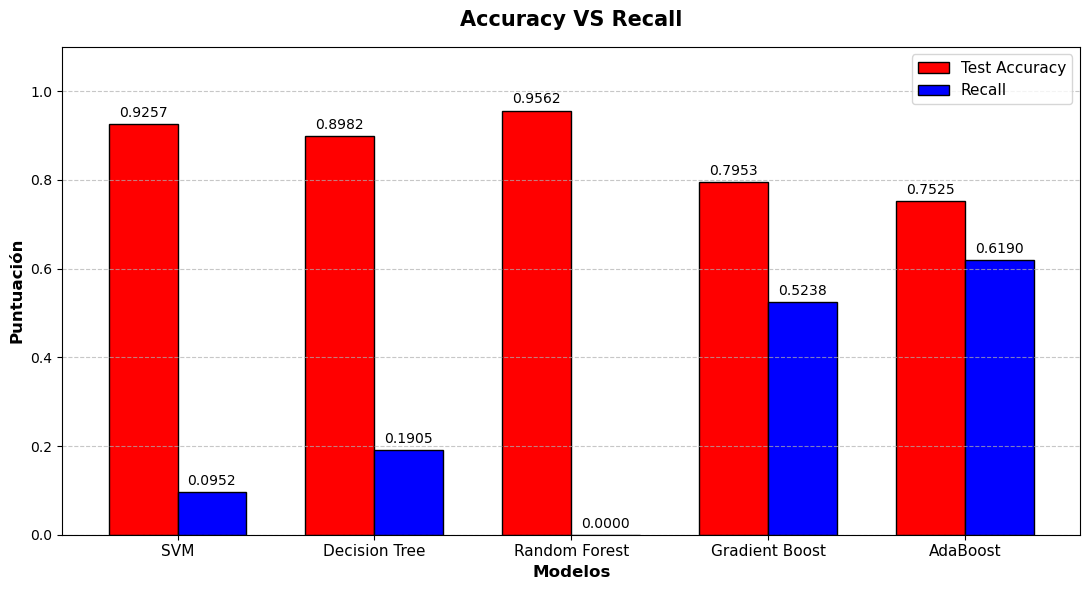

In [61]:
modelos = ['SVM', 'Decision Tree', 'Random Forest', 'Gradient Boost', 'AdaBoost']
accuracy = [0.9257, 0.8982, 0.9562, 0.7953, 0.7525]
recall = [0.0952, 0.1905, 0.0000, 0.5238, 0.6190]

x = np.arange(len(modelos))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

barras_acc = ax.bar(x - width/2, accuracy, width, label='Test Accuracy', color='red', edgecolor='black')
barras_recall = ax.bar(x + width/2, recall, width, label='Recall', color='blue', edgecolor='black')

ax.set_ylabel('Puntuación', fontsize=12, fontweight='bold')
ax.set_xlabel('Modelos', fontsize=12, fontweight='bold')
ax.set_title('Accuracy VS Recall', fontsize=15, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(modelos, fontsize=11)
ax.set_ylim(0, 1.1)
ax.legend(fontsize=11, loc='upper right')
ax.grid(axis='y', linestyle='--', alpha=0.7)

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10)

autolabel(barras_acc)
autolabel(barras_recall)

plt.tight_layout()
plt.savefig('accuracy_vs_recall.png', dpi=400)
plt.show()

#### Evolución del Sobreajuste (Overfitting) en Gradient Boosting

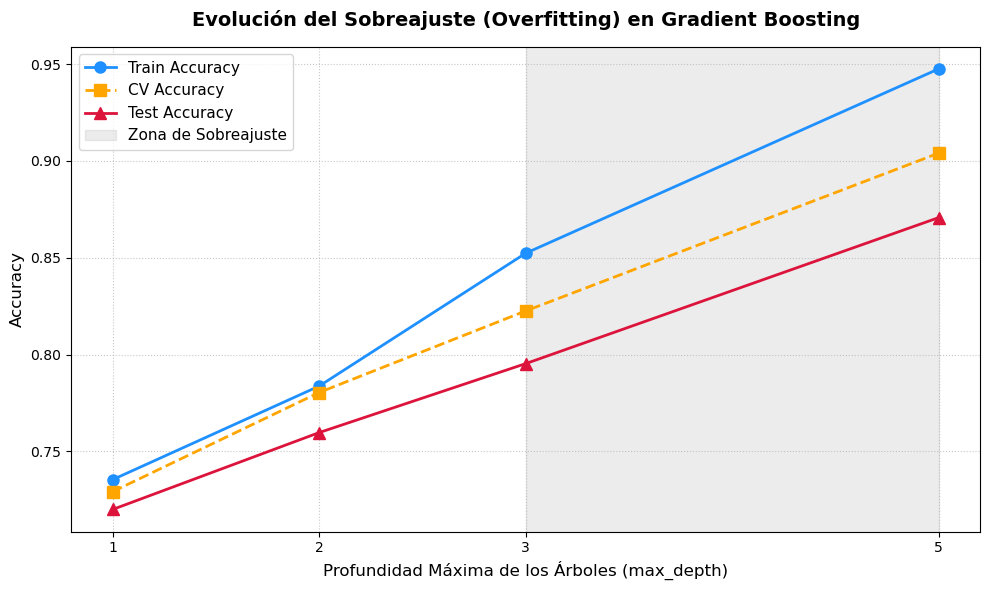

In [62]:
profundidades = [1, 2, 3, 5]
train_acc = [0.7354, 0.7837, 0.8523, 0.9475]
cv_acc =    [0.7292, 0.7804, 0.8225, 0.9040]
test_acc =  [0.7200, 0.7597, 0.7953, 0.8707]

plt.figure(figsize=(10, 6))

plt.plot(profundidades, train_acc, marker='o', linewidth=2, markersize=8, 
         label='Train Accuracy', color='dodgerblue')
plt.plot(profundidades, cv_acc, marker='s', linewidth=2, markersize=8, linestyle='--', 
         label='CV Accuracy', color='orange')
plt.plot(profundidades, test_acc, marker='^', linewidth=2, markersize=8, 
         label='Test Accuracy', color='crimson')

plt.title('Evolución del Sobreajuste (Overfitting) en Gradient Boosting', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Profundidad Máxima de los Árboles (max_depth)', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.xticks(profundidades)

plt.axvspan(3, 5, color='gray', alpha=0.15, label='Zona de Sobreajuste')

plt.legend(loc='upper left', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.savefig('evolucion_sobreajuste_gb.png', dpi=400)
plt.show()

#### Eficiencia: Tiempo de Entrenamiento vs Recall

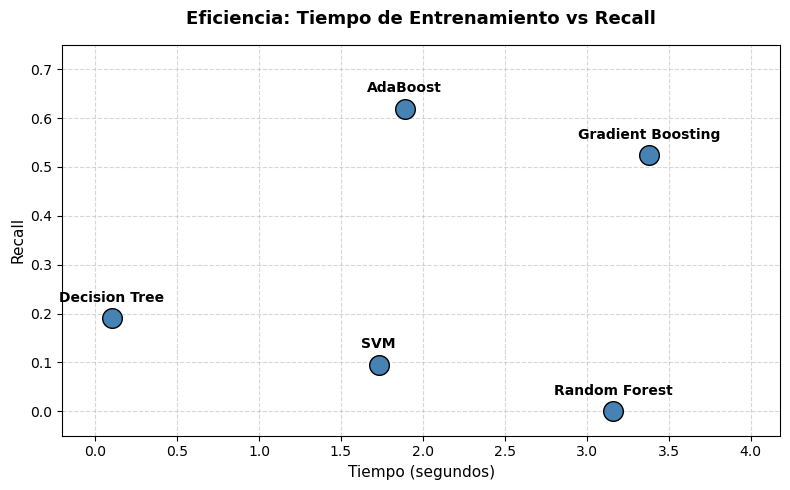

In [63]:
modelos = ['SVM', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'AdaBoost']
tiempos = [1.73, 0.10, 3.16, 3.38, 1.89]
recall = [0.0952, 0.1905, 0.0000, 0.5238, 0.6190]

plt.figure(figsize=(8, 5))

plt.scatter(tiempos, recall, color='steelblue', s=200, edgecolor='black', zorder=3)

for i in range(len(modelos)):
    plt.annotate(modelos[i], 
                 (tiempos[i], recall[i]), 
                 xytext=(0, 12),
                 textcoords='offset points', 
                 ha='center', 
                 fontsize=10,
                 fontweight='bold')

plt.title('Eficiencia: Tiempo de Entrenamiento vs Recall', fontweight='bold', fontsize=13, pad=15)
plt.xlabel('Tiempo (segundos)', fontsize=11)
plt.ylabel('Recall', fontsize=11)

plt.xlim(-0.2, max(tiempos) + 0.8)
plt.ylim(-0.05, 0.75)

plt.grid(True, linestyle='--', alpha=0.5, zorder=0)

plt.tight_layout()
plt.savefig('eficiencia.png', dpi=400)
plt.show()